<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Inspect expiry dates inside COSE envelopes

**Which decoded claims fall inside a review window, and which inputs cannot be dated?**
We will build synthetic CBOR claim sets, wrap them in COSE_Sign1 envelopes,
decode their typed fields with VGI, and use SQL to inventory expiration dates.
Missing, malformed and undated records remain visible alongside dated claims.

**This is structural inspection only.** Every constructed signature is a
64-byte zero placeholder. No signature is generated or verified, and no output
here is an authorization decision. The fixed audit clock is
**2026-11-14 00:00:00 UTC**, independent of when you run the notebook.

## Choose the forward review window

`HORIZON_DAYS` accepts whole days from **1 to 90**. Default **7**; experiment **30**.
A future expiry is in the window when **audit time < expiry ≤ deadline**.
An expiry at or before the audit time is already elapsed. Editing this parameter
changes the classification and deadline, while the original envelopes and decoded
dates stay fixed. Restart the kernel and run all.

In [1]:
HORIZON_DAYS = 7

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from notebook_support import finish, prose, theme

if (
    isinstance(HORIZON_DAYS, bool)
    or not isinstance(HORIZON_DAYS, int)
    or not 1 <= HORIZON_DAYS <= 90
):
    raise ValueError("HORIZON_DAYS must be a whole number from 1 through 90.")
STATUS_COLORS = {
    "Elapsed expiry": "#a85337",
    "Within review window": "#c57b40",
    "Beyond deadline": "#267358",
    "Expiry missing": "#73889a",
    "No decoded claims": "#8e81a5",
    "Malformed CBOR": "#665b58",
    "Missing input": "#aab8b0",
}
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-cbor/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-cbor/notebooks/pyproject.toml.

## Connect to the released structural decoders

The literal location selects the **v0.7.1** native release. VGI downloads,
verifies and caches it; no local Rust build is needed. The notebook locks
Haybarn **2.0.0rc11**. Initial installation requires network access, while the
following codec and structural-decoder calls use only bytes in memory.

The initial control decodes a simple CBOR array into diagnostic notation.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cbor' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-cbor@v0.7.1');
SELECT cbor.main.diagnostic(from_hex('83010203')) AS decoded_array;

,decoded_array
0,"[1, 2, 3]"


## Construct small, inspectable envelopes

The seed contains eight explicit expiry offsets and one missing expiry. Numeric
CWT map keys **1, 2 and 4** represent issuer, subject and expiration. SQL supplies
the small map/envelope framing bytes; **`cbor.encode` encodes each typed value**,
including the nested payload byte string.

`d2 84` starts a tagged COSE_Sign1 four-element array; `43 a1 01 26` carries the
protected ES256 algorithm label, and `a0` is an empty unprotected map. The final
byte string is an intentionally invalid placeholder signature. The algorithm
label describes the envelope's claim, not evidence that the bytes were signed.

The three extra controls are a truncated envelope, a valid CBOR integer that is
not a claims map, and a NULL input. All issuer/subject strings are synthetic.

In [5]:
%%sql
CREATE OR REPLACE TABLE seed AS
SELECT id, 'sensor-' || lpad(id::VARCHAR, 2, '0') AS subject, expiry_offset_days,
       TIMESTAMPTZ '2026-11-14 00:00:00+00' + expiry_offset_days * INTERVAL '1 day' AS expected_expiry
FROM (VALUES (1,-4), (2,0), (3,2), (4,7), (5,8), (6,21), (7,45), (8,90), (9,NULL)) t(id, expiry_offset_days);
CREATE OR REPLACE TABLE payloads AS
SELECT *,
       CASE WHEN expected_expiry IS NULL THEN from_hex('a201') ELSE from_hex('a301') END
       || cbor.main.encode('https://issuer.example')
       || from_hex('02') || cbor.main.encode(subject)
       || CASE WHEN expected_expiry IS NULL THEN from_hex('')
               ELSE from_hex('04') || cbor.main.encode(epoch(expected_expiry)::BIGINT) END AS payload
FROM seed;
CREATE OR REPLACE TABLE inbound AS
SELECT id, 'Synthetic envelope' AS input_kind,
       from_hex('d28443a10126a0') || cbor.main.encode(payload)
       || cbor.main.encode(from_hex(repeat('00',64))) AS token FROM payloads
UNION ALL SELECT 10, 'Truncated envelope', from_hex('d28443a10126a0')
UNION ALL SELECT 11, 'Integer control', from_hex('00')
UNION ALL SELECT 12, 'Missing input', NULL::BLOB;
SELECT id, subject, expiry_offset_days,
       expected_expiry AT TIME ZONE 'UTC' AS expected_expiry_utc FROM seed ORDER BY id;

,id,subject,expiry_offset_days,expected_expiry_utc
0,1,sensor-01,-4,2026-11-10
1,2,sensor-02,0,2026-11-14
2,3,sensor-03,2,2026-11-16
3,4,sensor-04,7,2026-11-21
4,5,sensor-05,8,2026-11-22
5,6,sensor-06,21,2026-12-05
6,7,sensor-07,45,2026-12-29
7,8,sensor-08,90,2027-02-12
8,9,sensor-09,<NA>,NaT


## Retain every input while decoding

Scalar decoders return a result per input row. `well_formed` reports outer CBOR
syntax, trailing-byte and duplicate-map-key problems. `cose_decode` exposes the
envelope; `cwt_claims` unwraps its payload into named fields, including typed
expiry timestamps. Successful decoding does not validate signature, issuer,
audience, required claims or trust policy.

We materialize those results before querying them again. The registry join is a
**left join**, so missing algorithm metadata cannot silently remove a row.

In [6]:
%%sql
CREATE OR REPLACE TABLE decoded AS
SELECT *, cbor.main.well_formed(token) AS diagnosis,
       cbor.main.cose_decode(token) AS envelope,
       cbor.main.cwt_claims(token) AS claims,
       cbor.main.cose_headers(token) AS headers
FROM inbound;
CREATE OR REPLACE TABLE algorithms AS
SELECT id, name FROM cbor.main.cose_registry WHERE registry = 'alg';
CREATE OR REPLACE TABLE inventory AS
SELECT d.*, a.id AS algorithm_id,
       claims.exp AT TIME ZONE 'UTC' AS expiry_utc,
       epoch(claims.exp - TIMESTAMPTZ '2026-11-14 00:00:00+00') / 86400.0 AS days_from_audit
FROM decoded d LEFT JOIN algorithms a ON a.name = d.headers.alg;
SELECT id, input_kind, diagnosis.ok AS outer_cbor_ok, diagnosis.kind AS parse_problem,
       envelope.msg_type AS envelope_type, headers.alg AS claimed_algorithm,
       algorithm_id, claims.sub AS subject, expiry_utc
FROM inventory ORDER BY id;

,id,input_kind,outer_cbor_ok,parse_problem,envelope_type,claimed_algorithm,algorithm_id,subject,expiry_utc
0,1,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-01,2026-11-10
1,2,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-02,2026-11-14
2,3,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-03,2026-11-16
3,4,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-04,2026-11-21
4,5,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-05,2026-11-22
5,6,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-06,2026-12-05
6,7,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-07,2026-12-29
7,8,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-08,2027-02-12
8,9,Synthetic envelope,True,None,COSE_Sign1,ES256,-7,sensor-09,NaT
9,10,Truncated envelope,False,truncated,None,None,<NA>,None,NaT


## Check the decoded values against their construction

The seed provides an independent expectation for the returned subject and expiry
fields. We also check that registry enrichment preserves rows and that the
placeholder signature survives structural decoding unchanged. These checks test
the walkthrough's data handling; none performs cryptographic verification.

In [7]:
%%sql checks <<
SELECT 'Every input survives enrichment' AS check_name,
       abs((SELECT count(*) FROM inbound) - (SELECT count(*) FROM inventory)) AS violations
UNION ALL
SELECT 'Unique IDs survive the registry join', count(*) FROM (
 SELECT id FROM inventory GROUP BY id HAVING count(*) <> 1
)
UNION ALL
SELECT 'Constructed subjects and issuers decode exactly', count(*) FROM inventory i JOIN seed s USING(id)
 WHERE i.claims.sub IS DISTINCT FROM s.subject OR i.claims.iss IS DISTINCT FROM 'https://issuer.example'
UNION ALL
SELECT 'Decoded expiry agrees with the typed seed, including NULL', count(*) FROM inventory i JOIN seed s USING(id)
 WHERE i.claims.exp IS DISTINCT FROM s.expected_expiry
UNION ALL
SELECT 'Constructed envelopes decode as Sign1', count(*) FROM inventory i JOIN seed s USING(id)
 WHERE i.envelope.msg_type IS DISTINCT FROM 'COSE_Sign1' OR i.envelope.tag IS DISTINCT FROM 18
UNION ALL
SELECT 'Placeholder signatures remain zero bytes', count(*) FROM inventory i JOIN seed s USING(id)
 WHERE i.envelope.signature IS DISTINCT FROM from_hex(repeat('00',64))
UNION ALL
SELECT 'CBOR integer is well formed but has no decoded claims', count(*) FROM inventory WHERE input_kind = 'Integer control'
 AND (diagnosis.ok IS DISTINCT FROM TRUE OR claims IS NOT NULL)
UNION ALL
SELECT 'Missing input stays NULL throughout decoding', count(*) FROM inventory WHERE input_kind = 'Missing input'
 AND (diagnosis IS NOT NULL OR claims IS NOT NULL OR envelope IS NOT NULL);

In [8]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), (
    "Decoded fields or inventory preservation changed."
)
prose(
    f"All **{len(checks)} checks pass**, including exact decoded expiry timestamps and the zero-byte signature placeholders. The decoder exposes those placeholders successfully; the result establishes structure, not authenticity."
)

,check_name,violations
0,Every input survives enrichment,0
1,Unique IDs survive the registry join,0
2,Constructed subjects and issuers decode exactly,0
3,"Decoded expiry agrees with the typed seed, inc...",0
4,Constructed envelopes decode as Sign1,0
5,Placeholder signatures remain zero bytes,0
6,CBOR integer is well formed but has no decoded...,0
7,Missing input stays NULL throughout decoding,0


All **8 checks pass**, including exact decoded expiry timestamps and the zero-byte signature placeholders. The decoder exposes those placeholders successfully; the result establishes structure, not authenticity.

## Assign an inventory disposition without losing unknowns

SQL handles missing input and decode failures before looking at expiration.
A decoded map with no expiry stays **Expiry missing**; it is not classified as
elapsed or beyond the deadline. An expiry exactly at the audit time is elapsed,
and the forward window includes its upper deadline.

The statuses below describe **claimed dates in unverified input**. They are a
review inventory, not acceptance or rejection decisions for a token.

In [9]:
%%sql
CREATE OR REPLACE TABLE reviewed AS
SELECT *, CASE
 WHEN token IS NULL THEN 'Missing input'
 WHEN diagnosis.ok IS DISTINCT FROM TRUE THEN 'Malformed CBOR'
 WHEN claims IS NULL THEN 'No decoded claims'
 WHEN claims.exp IS NULL THEN 'Expiry missing'
 WHEN claims.exp <= TIMESTAMPTZ '2026-11-14 00:00:00+00' THEN 'Elapsed expiry'
 WHEN claims.exp <= TIMESTAMPTZ '2026-11-14 00:00:00+00' + {{ HORIZON_DAYS }} * INTERVAL '1 day' THEN 'Within review window'
 ELSE 'Beyond deadline' END AS disposition
FROM inventory;
SELECT id, input_kind, claims.sub AS subject, expiry_utc, days_from_audit, disposition
FROM reviewed ORDER BY id;

,id,input_kind,subject,expiry_utc,days_from_audit,disposition
0,1,Synthetic envelope,sensor-01,2026-11-10,-4.0,Elapsed expiry
1,2,Synthetic envelope,sensor-02,2026-11-14,0.0,Elapsed expiry
2,3,Synthetic envelope,sensor-03,2026-11-16,2.0,Within review window
3,4,Synthetic envelope,sensor-04,2026-11-21,7.0,Within review window
4,5,Synthetic envelope,sensor-05,2026-11-22,8.0,Beyond deadline
5,6,Synthetic envelope,sensor-06,2026-12-05,21.0,Beyond deadline
6,7,Synthetic envelope,sensor-07,2026-12-29,45.0,Beyond deadline
7,8,Synthetic envelope,sensor-08,2027-02-12,90.0,Beyond deadline
8,9,Synthetic envelope,sensor-09,NaT,NaN,Expiry missing
9,10,Truncated envelope,None,NaT,NaN,Malformed CBOR


In [10]:
%%sql summary <<
SELECT ordering, disposition, count(r.id) AS records
FROM (VALUES (1,'Elapsed expiry'), (2,'Within review window'), (3,'Beyond deadline'),
             (4,'Expiry missing'), (5,'No decoded claims'), (6,'Malformed CBOR'), (7,'Missing input')) categories(ordering, disposition)
LEFT JOIN reviewed r USING(disposition) GROUP BY ordering, disposition ORDER BY ordering;

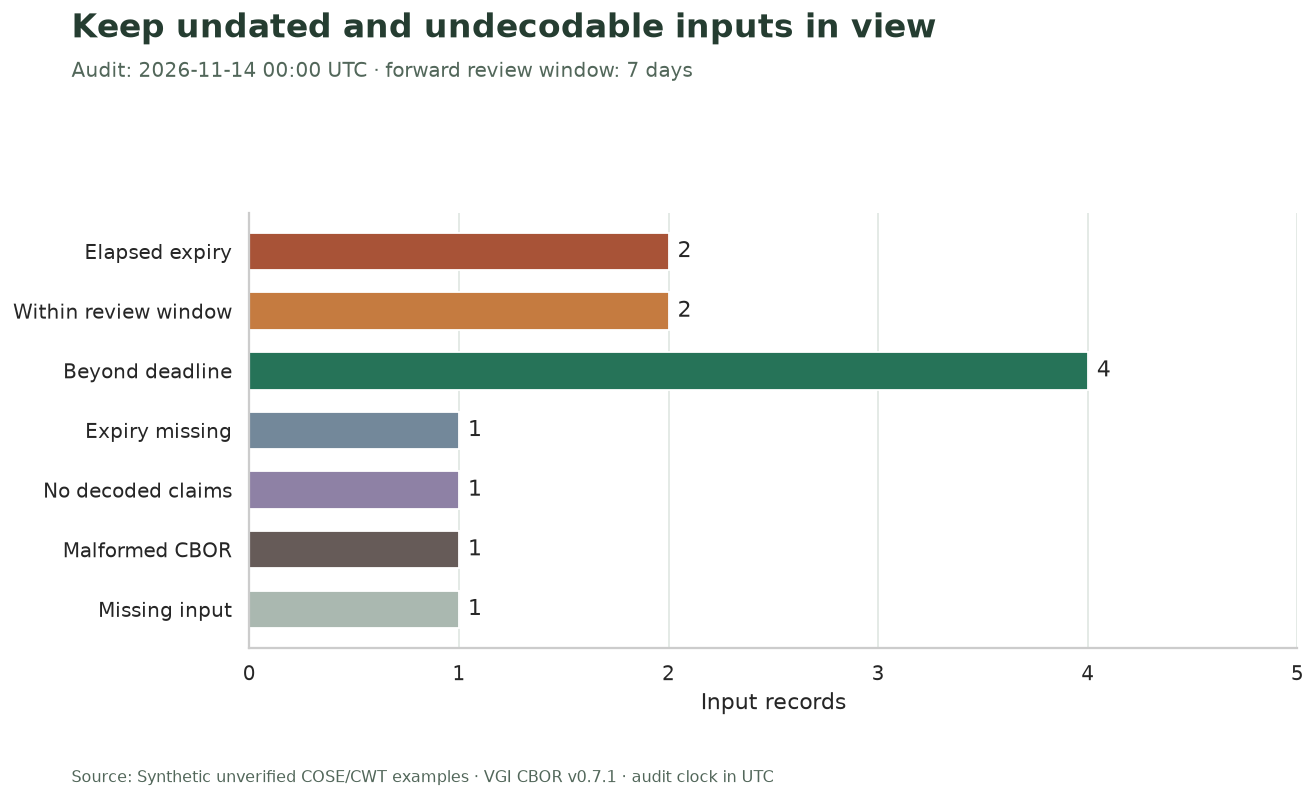

The inventory retains **12 records**. **2** have a claimed future expiry inside the selected window, **2** have elapsed, and **4** cannot be placed on the expiry timeline. Those undated records remain separate review categories.

In [11]:
summary = globals()["summary"]
fig, ax = plt.subplots(figsize=(10.5, 6.2))
y = np.arange(len(summary))
bars = ax.barh(
    y,
    summary.records,
    color=[STATUS_COLORS[s] for s in summary.disposition],
    height=0.63,
)
ax.bar_label(bars, padding=5, fmt="%.0f")
ax.set(
    yticks=y,
    yticklabels=summary.disposition,
    xlabel="Input records",
    ylabel="",
    xlim=(0, max(1, summary.records.max()) + 1),
)
ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Keep undated and undecodable inputs in view",
    f"Audit: 2026-11-14 00:00 UTC · forward review window: {HORIZON_DAYS} days",
    f"inventory-{HORIZON_DAYS}.png",
)
counts = summary.set_index("disposition").records
undated = int(
    counts[
        ["Expiry missing", "No decoded claims", "Malformed CBOR", "Missing input"]
    ].sum()
)
prose(
    f"The inventory retains **{int(summary.records.sum())} records**. **{int(counts['Within review window'])}** have a claimed future expiry inside the selected window, **{int(counts['Elapsed expiry'])}** have elapsed, and **{undated}** cannot be placed on the expiry timeline. Those undated records remain separate review categories."
)

## Plot dates only where the decoder returned a date

The horizontal axis is signed days from the fixed audit clock. Red points have
elapsed; amber points are inside the selected forward window; green points are
beyond it. The dashed line is the inclusive deadline. A point at zero is an actual
expiry at the audit instant, not a substitute for a missing date.

Only rows with returned expiry timestamps appear here; the previous chart keeps
the omitted records visible.

In [12]:
%%sql dated <<
SELECT id, claims.sub AS subject, expiry_utc, days_from_audit, disposition
FROM reviewed WHERE claims.exp IS NOT NULL ORDER BY days_from_audit, id;

,id,subject,expiry_utc,days_from_audit,disposition
0,1,sensor-01,2026-11-10,-4.0,Elapsed expiry
1,2,sensor-02,2026-11-14,0.0,Elapsed expiry
2,3,sensor-03,2026-11-16,2.0,Within review window
3,4,sensor-04,2026-11-21,7.0,Within review window
4,5,sensor-05,2026-11-22,8.0,Beyond deadline
5,6,sensor-06,2026-12-05,21.0,Beyond deadline
6,7,sensor-07,2026-12-29,45.0,Beyond deadline
7,8,sensor-08,2027-02-12,90.0,Beyond deadline


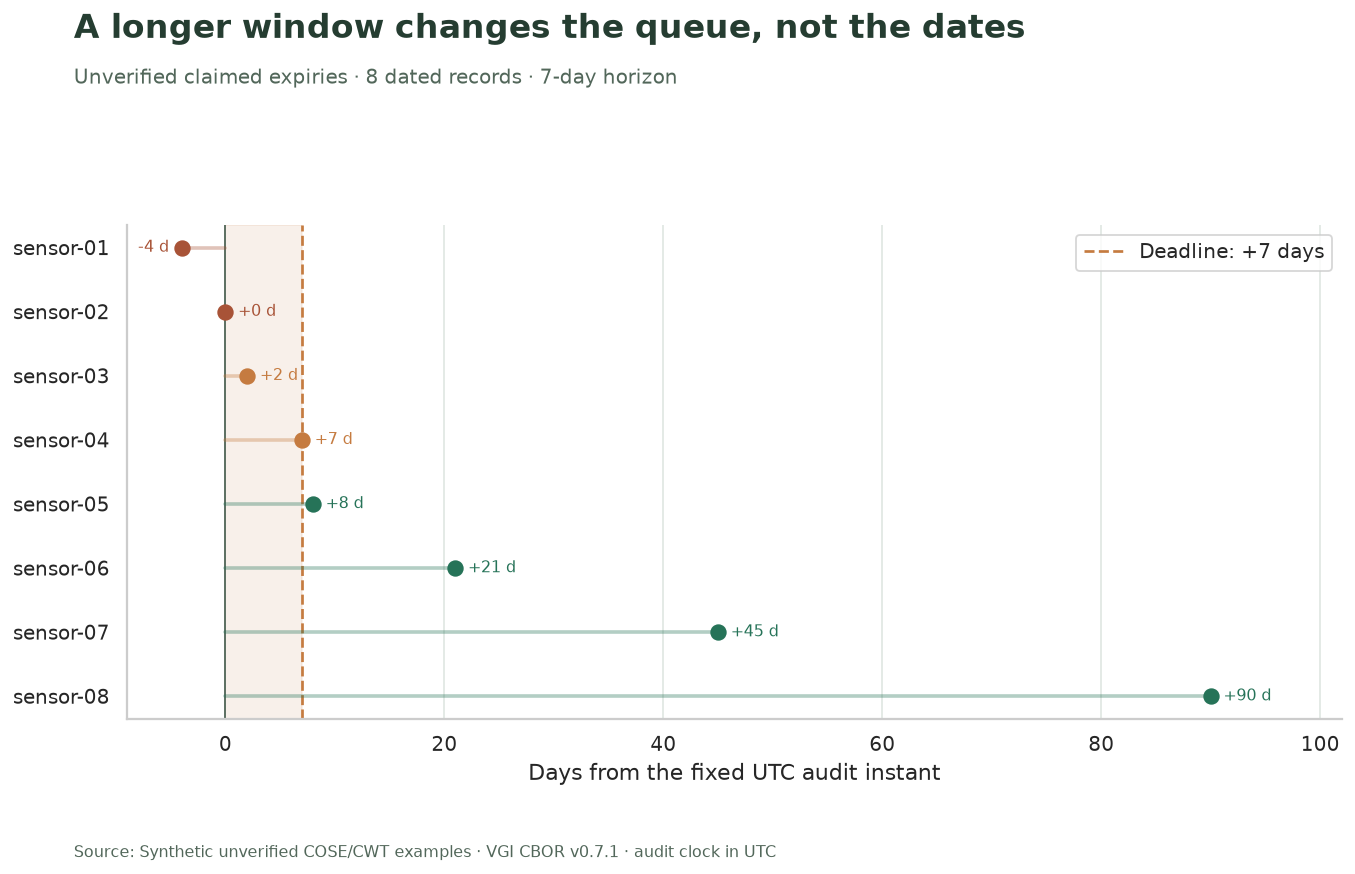

The dated subset contains **8 records**, from **-4** to **+90 days** relative to the audit clock. Moving the deadline recolors existing points; it does not alter the envelopes, decoded timestamps or missing-input categories.

In [13]:
dated = globals()["dated"]
display(dated)
y = np.arange(len(dated))
fig, ax = plt.subplots(figsize=(10.8, 6.8))
ax.axvspan(0, HORIZON_DAYS, color="#c57b40", alpha=0.11)
ax.axvline(0, color="#52675a", linewidth=1)
ax.axvline(
    HORIZON_DAYS,
    color="#c57b40",
    linestyle="--",
    linewidth=1.5,
    label=f"Deadline: +{HORIZON_DAYS} days",
)
for i, row in enumerate(dated.itertuples()):
    color = STATUS_COLORS[row.disposition]
    ax.plot([0, row.days_from_audit], [i, i], color=color, alpha=0.35, linewidth=2)
    ax.scatter(row.days_from_audit, i, color=color, s=65, zorder=3)
    ax.annotate(
        f"{row.days_from_audit:+.0f} d",
        (row.days_from_audit, i),
        xytext=(7 if row.days_from_audit >= 0 else -7, 0),
        ha="left" if row.days_from_audit >= 0 else "right",
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=color,
    )
ax.set(
    yticks=y,
    yticklabels=dated.subject,
    xlabel="Days from the fixed UTC audit instant",
    ylabel="",
    xlim=(
        min(-8, dated.days_from_audit.min() - 5),
        max(HORIZON_DAYS, dated.days_from_audit.max()) + 12,
    ),
)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", frameon=True)
finish(
    fig,
    "A longer window changes the queue, not the dates",
    f"Unverified claimed expiries · {len(dated)} dated records · {HORIZON_DAYS}-day horizon",
    f"expiries-{HORIZON_DAYS}.png",
)
prose(
    f"The dated subset contains **{len(dated)} records**, from **{dated.days_from_audit.min():+.0f}** to **{dated.days_from_audit.max():+.0f} days** relative to the audit clock. Moving the deadline recolors existing points; it does not alter the envelopes, decoded timestamps or missing-input categories."
)

## Experiment: expand the review window

Change only **`HORIZON_DAYS = 30`**, restart and run all. Predict which points
will enter the forward window. Compare the amber count, deadline line and point
colors; the decoded table, point positions and elapsed/undated counts should stay
fixed. Reset to **7**.

This workflow is useful for inspecting format and claimed metadata before a
separate verification step. For actual token decisions, signature validation,
issuer/audience policy and the application's required-claim rules still need to
be evaluated by an appropriate verifier. A recognized algorithm label and a
future expiry alone establish none of those properties.

In [14]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)